# Heart Disease UCI — Exploratory Data Analysis
Run `python -m src.data --output data/heart.csv` first.

In [1]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from src.data import FEATURES
df = pd.read_csv('../data/heart.csv')
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [2]:
print(df.isna().sum())
df.describe().T

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Class balance
`target`: 0 = no disease, 1 = disease (original values 1-4 collapsed).

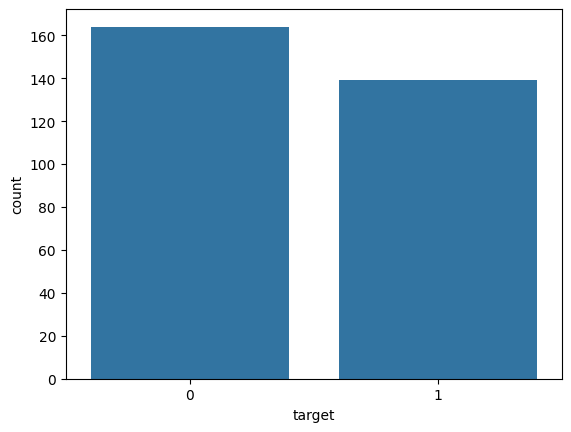

target
0    0.541254
1    0.458746
Name: proportion, dtype: float64

In [3]:
sns.countplot(data=df, x='target'); plt.show()
df.target.value_counts(normalize=True)

## Feature distributions

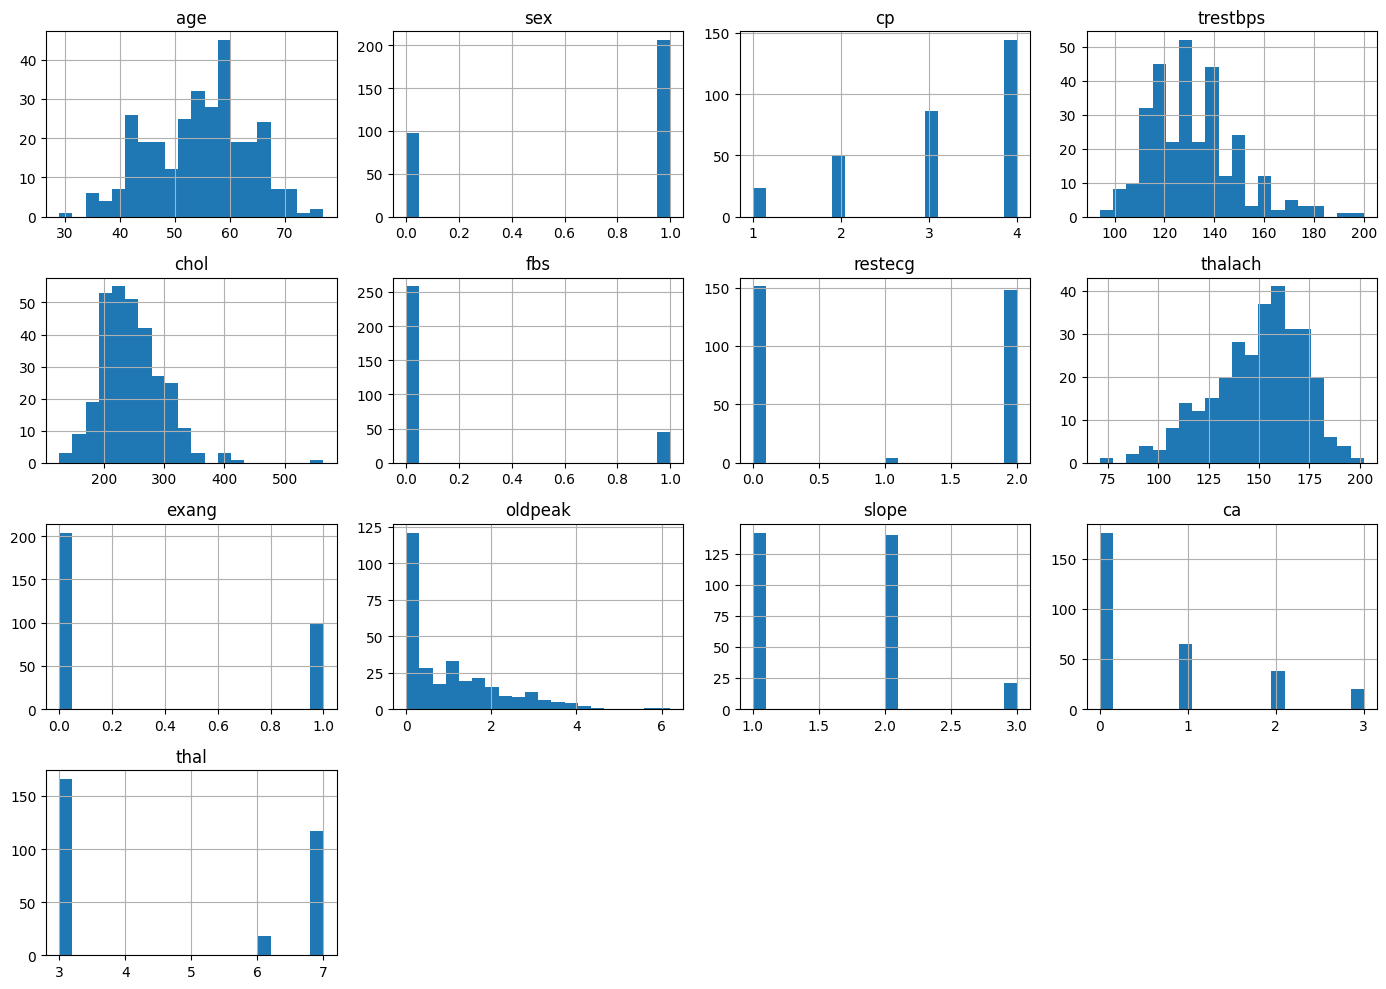

In [4]:
df[FEATURES].hist(figsize=(14,10), bins=20); plt.tight_layout(); plt.show()

## Correlation heatmap

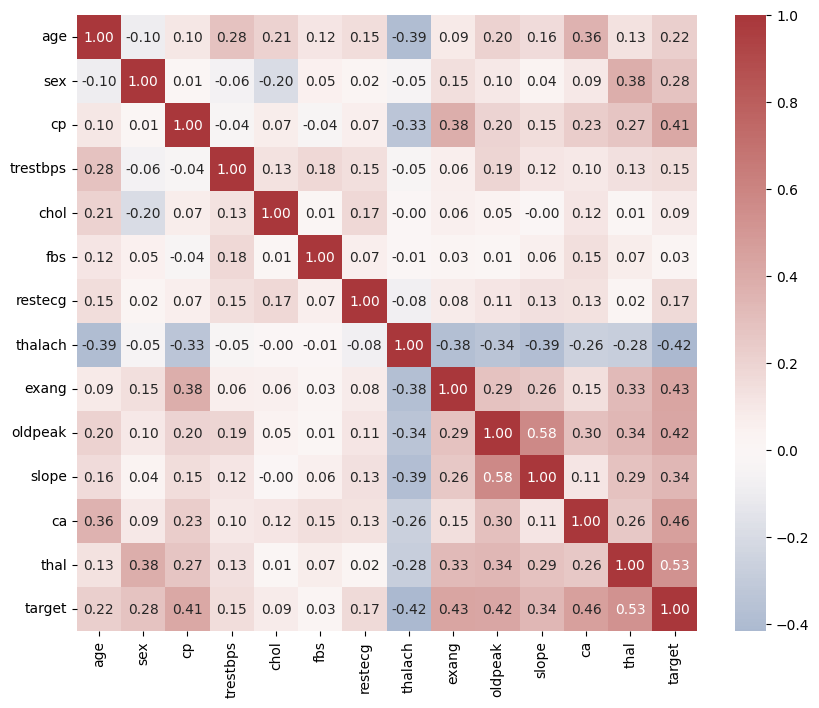

In [5]:
plt.figure(figsize=(10,8)); sns.heatmap(df.corr(numeric_only=True), cmap='vlag', center=0, annot=True, fmt='.2f'); plt.show()

## Features vs target

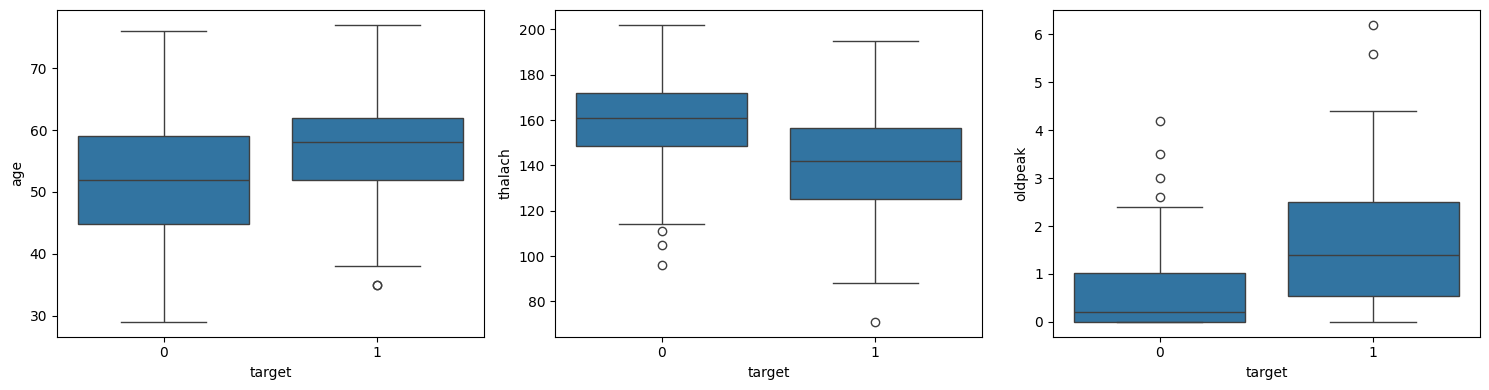

In [6]:
fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax, col in zip(axes, ['age','thalach','oldpeak']):
    sns.boxplot(data=df, x='target', y=col, ax=ax)
plt.tight_layout(); plt.show()

## Inference example

In [7]:
import joblib
model = joblib.load('../models/heart_pipeline.joblib')
sample = df[FEATURES].iloc[[0]]
print(model.predict(sample), model.predict_proba(sample))

[0] [[0.54114507 0.45885493]]
